# Experiment I: Analysis Notebook

This notebook reproduces the analysis of Experiment I in the paper
"Bayesian modeling of room-acoustic memory with same and different speech
signals".

The analysis has two parts:

1. **Similarity graph and communities.** Rooms with too few similarity
   relations are removed, and the Girvan-Newman algorithm is used to find
   communities of perceptually similar rooms ( resulting in communities A, B, and C in the
   paper).
2. **Room-acoustic parameters.** The distribution of the room-acoustic
   parameters of the dataset is summarized, and PCA followed by LDA is used
   to place the rooms of the graph in a two-dimensional parameter space for
   visualization.

**Data** (from `data/`):

- `adjacency_matrix.csv`: weighted adjacency matrix of the similarity graph.
- `node_labels.json`: room identifier of each node.
- `allParams.csv`: room-acoustic parameters of each room in octave bands.

**Figures** (saved to `doc/figs/` when `savePlots` is `True`):

| File | Content | Paper |
|---|---|---|
| `RoomAcousticParams.pdf` | Distribution of the room-acoustic parameters | Fig. 1 |
| `exp01_communities.pdf` | Similarity graph with communities in the parameter space | Fig. 3 |
| `exp01_aggregatedGraph.pdf` | Full similarity graph | x |
| `exp01_reducedGraph.pdf` | Graph after removing weakly connected rooms | x |
| `exp01_communities1.pdf` | Communities on the graph layout | x |

Run the notebook from its own folder (`code/experiment1`), since all paths
are relative to it. The Python environment is described in
`environment.yml`.

In [76]:
import numpy as np
import json

import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from netgraph import Graph
import re

import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Use Latin Modern Roman when it is installed, and another serif font otherwise.
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Latin Modern Roman', 'CMU Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'pdf.fonttype': 42,
})


In [77]:
# Set to True to save the figures in doc/figs
savePlots = False

# Locations
dataDir = '../../data/';
figsDir = '../../doc/figs/';
output = '../../scratch/experiment1';

## Similarity graph

Each node of the graph represents a room, with its unique identifier. The prefix of the identifier is the room category from in Tab. I in the paper. An edge connects two rooms if a participant placed them in the same cluster.

In [78]:
# Read the graph data
adj_matrix = np.loadtxt( dataDir + 'adjacency_matrix.csv', delimiter=',')
with open(dataDir + 'node_labels.json', 'r') as f:
    nodeLabels = json.load(f)

nodeLabels = {int(k): v for k, v in nodeLabels.items()}

In [79]:
# Create the graph
G = nx.Graph(adj_matrix);
G = nx.relabel_nodes(G, nodeLabels);

Plot of the full graph with a force-directed layout, where strongly connected rooms are drawn close to each other.

/opt/homebrew/Caskroom/miniconda/base/envs/room-acoustic-memory/lib/python3.9/site-packages/netgraph/_utils.py:360: RuntimeWarning: invalid value encountered in divide
  v = v / np.linalg.norm(v, axis=-1)[:, None] # unit vector


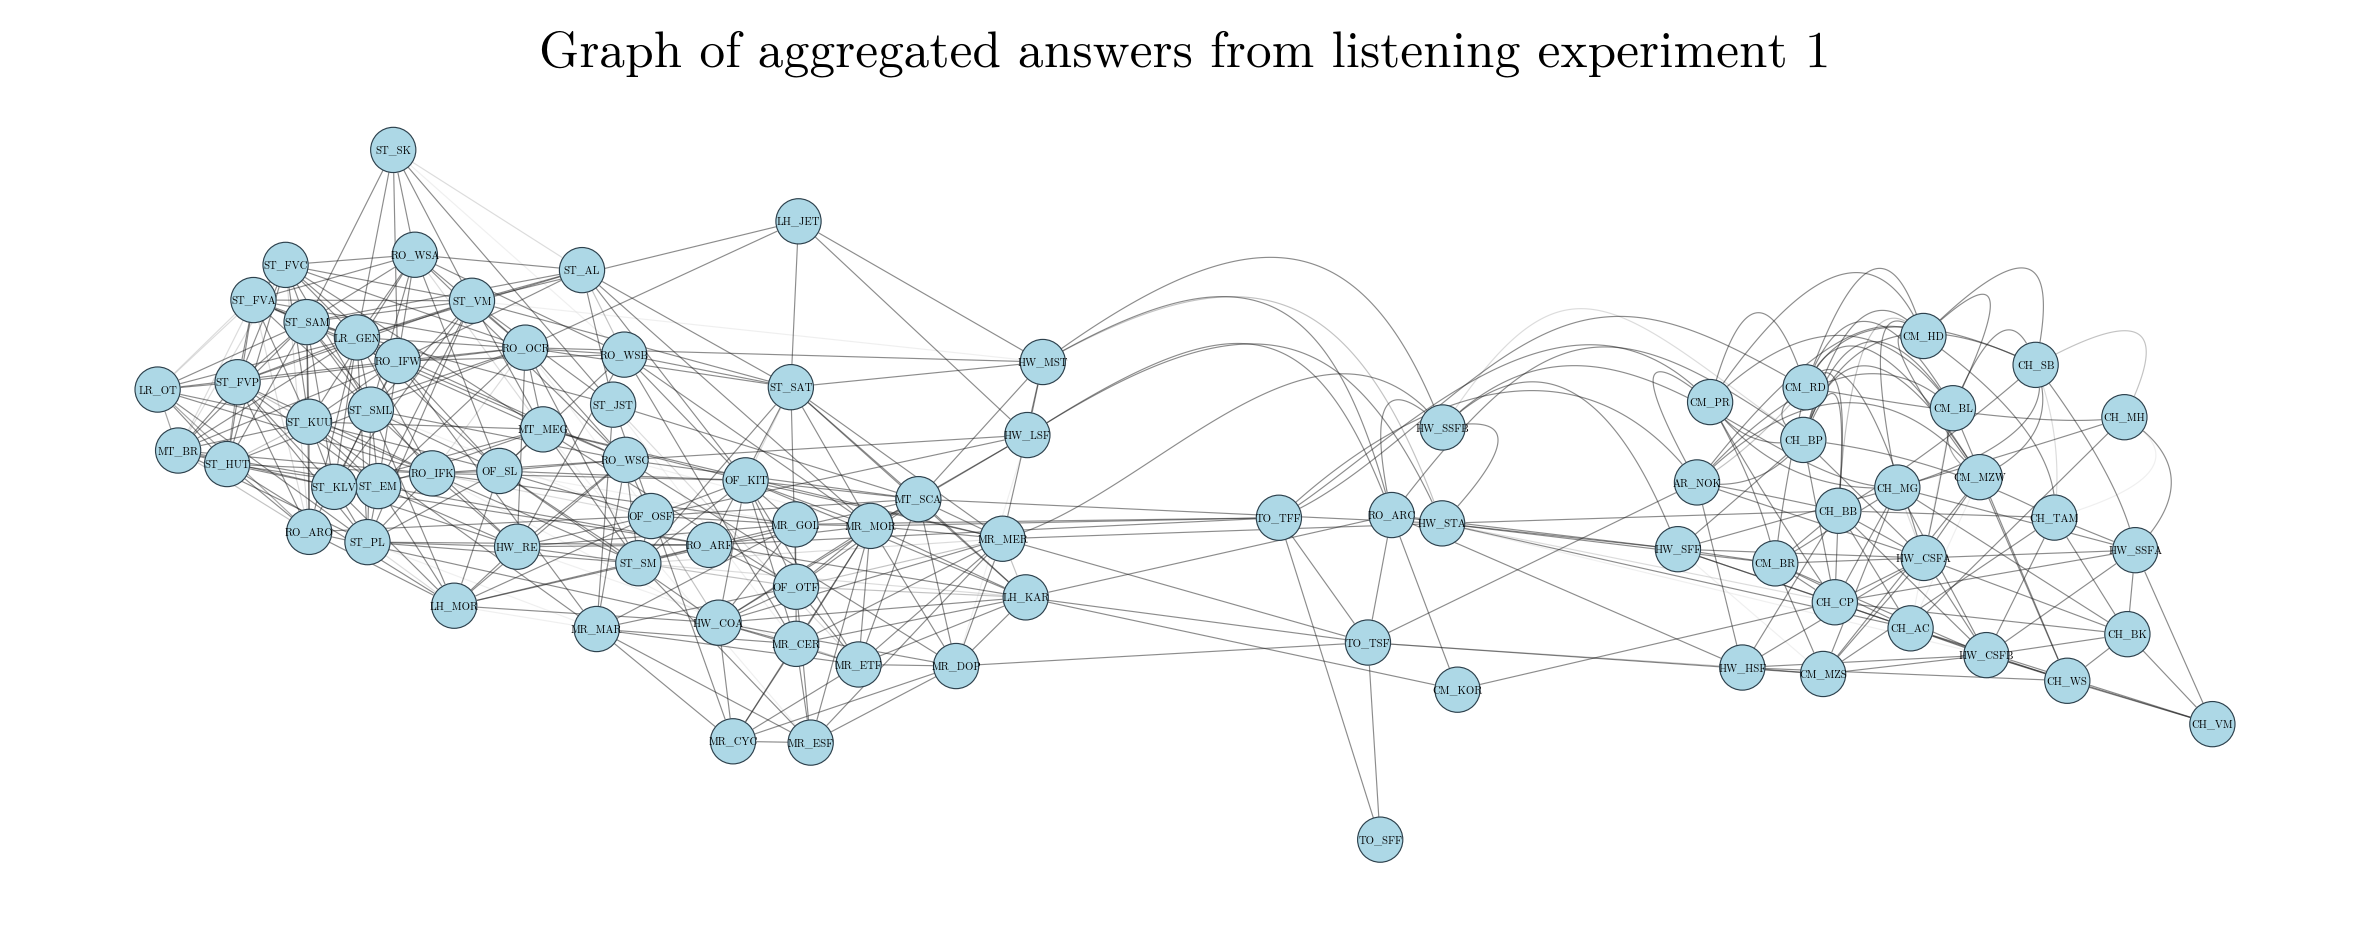

In [80]:
pos = nx.spring_layout(G, seed=12, k = 1/np.sqrt(80)+0.05, iterations=600) 

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
Graph(G, node_layout = pos,
      node_size=2,
      node_labels=True,
      node_color='lightblue',
      node_label_fontdict={"size": 2.5},
      node_edge_width=0.1,
      edge_width=0.1,
      edge_layout='curved',
      ax=ax)
ax.set_title("Graph of aggregated answers from listening experiment 1", fontsize=12)
plt.tight_layout()
if savePlots:
    plt.savefig( figsDir + 'exp01_aggregatedGraph.pdf', bbox_inches='tight', dpi=300)
plt.show()

## Removing weakly connected rooms

Rooms whose weighted degree is below the first quartile of the degree distribution are removed from the graph.

In [81]:
# Get the weighted degree of each node
weighted_degrees = dict(nx.degree(G, weight='weight'))
weighted_degrees_values = list(weighted_degrees.values())

# Compute some stats
mean_degree = np.mean(weighted_degrees_values)
min_degree = np.min(weighted_degrees_values)
max_degree = np.max(weighted_degrees_values)
median_degree = np.median(weighted_degrees_values)

#iqr
# Compute the 25th and 75th percentiles
q1 = np.percentile(weighted_degrees_values, 25)
q3 = np.percentile(weighted_degrees_values, 75)

# Compute the interquartile range (IQR)
iqr = q3 - q1

print("Mean Degree:", mean_degree)
print("Minimum Degree:", min_degree)
print("Maximum Degree:", max_degree)
print("Median Degree:", median_degree)
print("Interquartile Range (IQR):", iqr)


# Now we get rid of the nodes that are not densely conncected to the graph, thoses whose degree is below the first quartile.

# Define the lower and upper fences
lower_fence = q1
upper_fence = max_degree + 1

# Identify potential outliers
outliers = [degree for degree in weighted_degrees_values if degree < lower_fence or degree > upper_fence]
outlier_indices = [index for index, degree in enumerate(weighted_degrees_values) if degree < lower_fence or degree > upper_fence]

outlier_keys = [nodeLabels[key] for key in outlier_indices]

print("Lower Fence:", lower_fence)
print("Upper Fence:", upper_fence)
print("Potential Outlier weights:", outliers)
print("Potential Outlier indices:", outlier_indices)
print("Potential Outlier keys:", outlier_keys)

# Remove all nodes that fall outsede of the defined fences
G.remove_nodes_from(outlier_keys)

Mean Degree: 11.355
Minimum Degree: 2.0
Maximum Degree: 18.6
Median Degree: 11.2
Interquartile Range (IQR): 4.799999999999999
Lower Fence: 9.0
Upper Fence: 19.6
Potential Outlier weights: [2.0, 6.6000000000000005, 8.0, 8.799999999999999, 6.4, 7.6, 8.2, 5.0, 8.2, 8.2, 8.6, 8.0, 7.6000000000000005, 7.6, 7.0, 5.0, 3.0, 8.0, 4.8]
Potential Outlier indices: [3, 13, 22, 25, 26, 28, 32, 34, 37, 39, 44, 45, 46, 49, 54, 58, 70, 71, 78]
Potential Outlier keys: ['TO_SFF', 'ST_SK', 'TO_TFF', 'HW_MST', 'HW_SSFB', 'HW_HSF', 'MR_ESF', 'LH_JET', 'HW_LSF', 'CM_MZS', 'TO_TSF', 'CH_BK', 'CH_TAM', 'ST_JST', 'CH_WS', 'CH_VM', 'CM_KOR', 'MR_CYC', 'CH_MH']


Plot of the reduced graph, with force-directed layout.

/opt/homebrew/Caskroom/miniconda/base/envs/room-acoustic-memory/lib/python3.9/site-packages/netgraph/_utils.py:360: RuntimeWarning: invalid value encountered in divide
  v = v / np.linalg.norm(v, axis=-1)[:, None] # unit vector


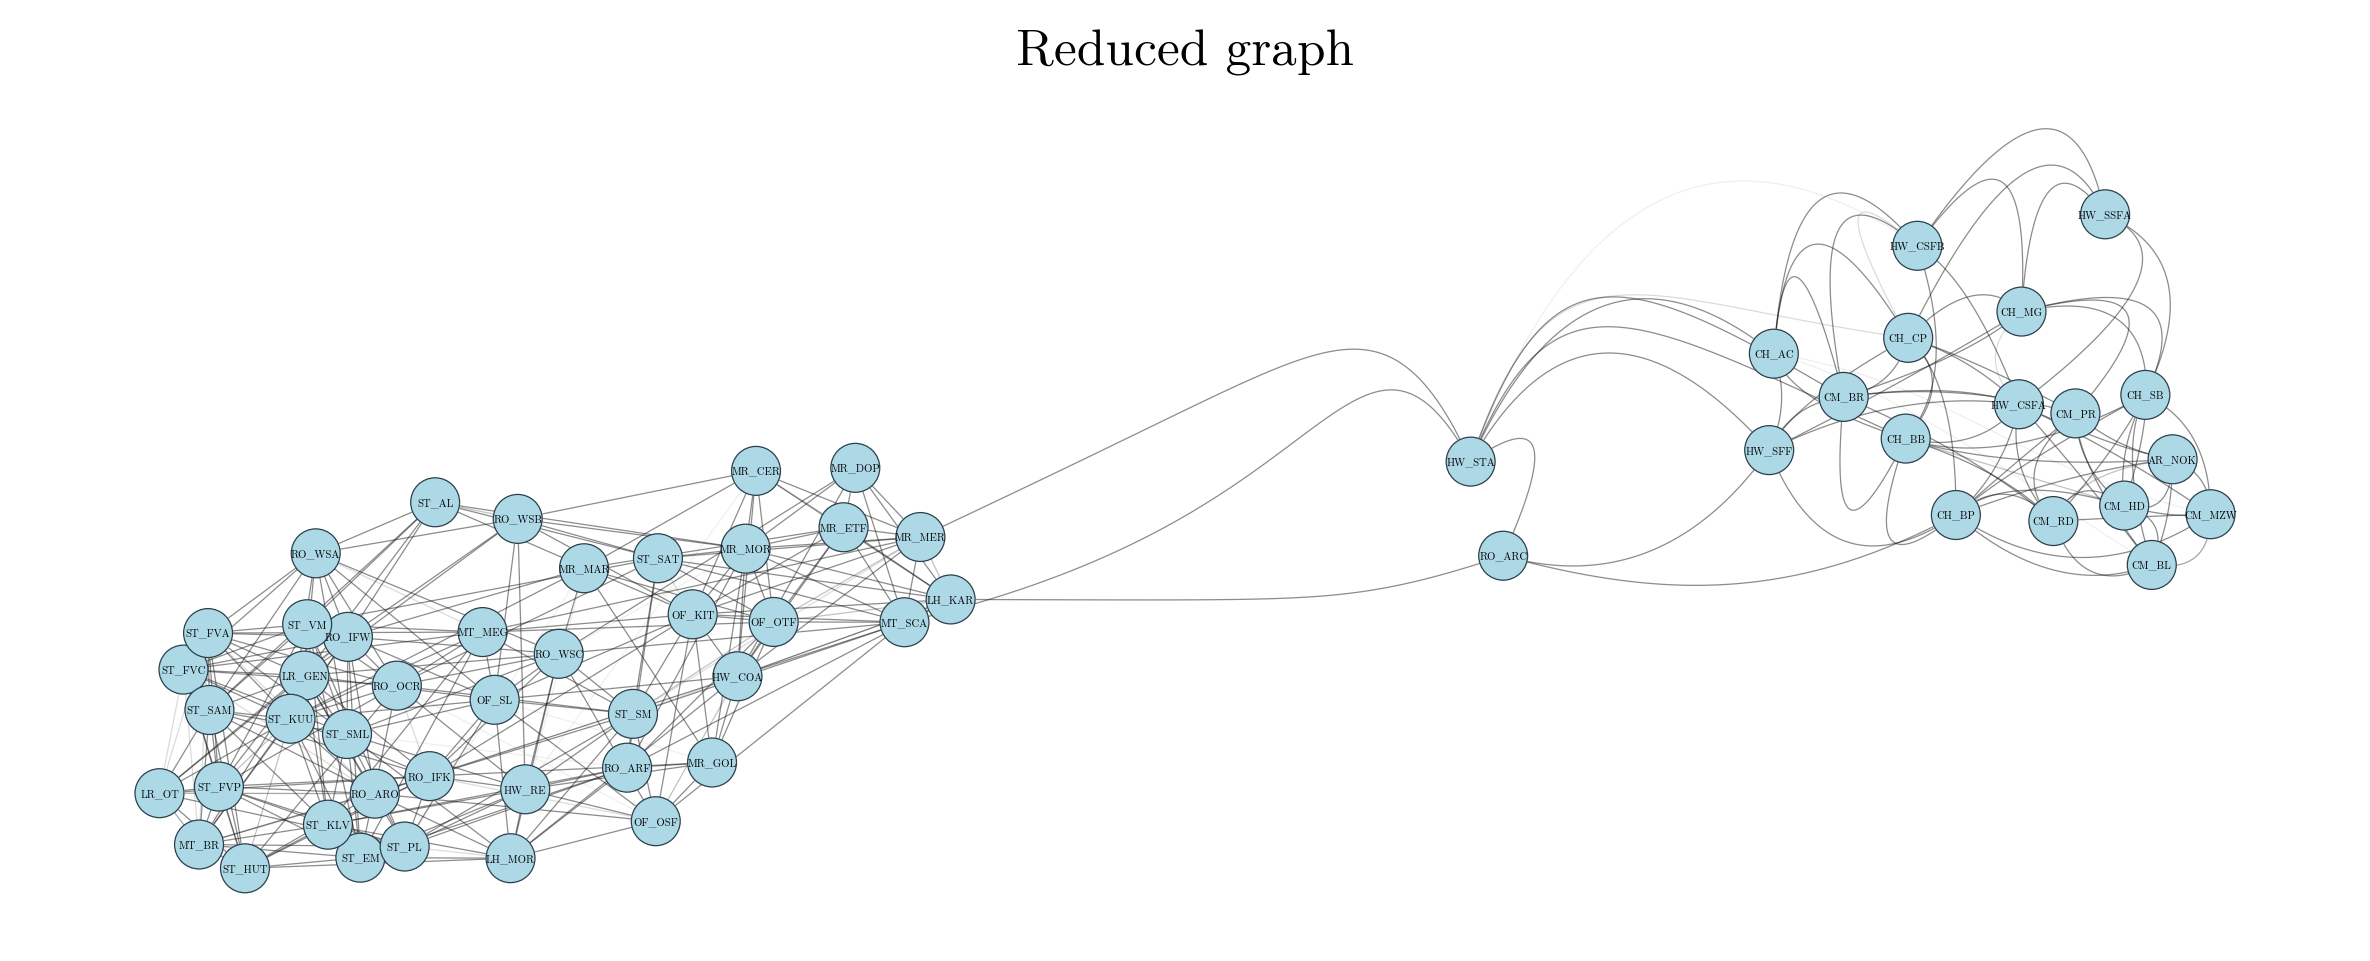

In [82]:
# Plot the reduced graph
pos = nx.spring_layout(G, seed=9, k = 1/np.sqrt(80)+0.05)
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
Graph(G, node_layout = pos,
      node_size=2,
      node_labels=True,
      node_color='lightblue',
      node_label_fontdict={"size": 2.5},
      node_edge_width=0.1,
      edge_width=0.1,
      edge_layout='curved',
      ax=ax)
ax.set_title("Reduced graph", fontsize=12)
plt.tight_layout()
if savePlots:
    plt.savefig(figsDir + 'exp01_reducedGraph.pdf', bbox_inches='tight', dpi=300)
plt.show()

## Girvan-Newman community detection

The Girvan-Newman algorithm splits the graph into communities by repeatedly
removing the edge with the highest betweenness, i.e., the edge that lies on
the most shortest paths between rooms. Each iteration gives a partition of
the graph, and we keep the one with the highest modularity $Q$. Modularity $Q$
measures how much denser the connections are within communities compared to between them.

The best partition has three communities ($Q = 0.46$), after two iterations
of the algorithm. In the order returned by the algorithm, they correspond to
communities A (30 rooms), B (12 rooms), and C (19 rooms) of the paper.

In [83]:
# Compute communities
all_communities = list(nx.community.girvan_newman(G))

modularities = [
    nx.community.modularity(G, comms)
    for comms in all_communities
]

best_idx = max(range(len(modularities)), key=lambda i: modularities[i])
best_modularity = modularities[best_idx]
communities = all_communities[best_idx]

print("Best index:", best_idx)
print("Best modularity:", best_modularity)
print("Best partition:", communities)

Best index: 1
Best modularity: 0.4607779558382942
Best partition: ({'RO_OCR', 'RO_WSC', 'OF_SL', 'RO_IFW', 'ST_EM', 'ST_FVC', 'ST_SML', 'MR_MAR', 'ST_FVA', 'ST_FVP', 'ST_KUU', 'HW_RE', 'MT_MEG', 'ST_PL', 'LH_MOR', 'RO_ARO', 'ST_KLV', 'MT_BR', 'RO_ARF', 'RO_WSA', 'RO_WSB', 'ST_HUT', 'ST_VM', 'LR_OT', 'RO_IFK', 'ST_SAM', 'ST_SM', 'OF_OSF', 'ST_AL', 'LR_GEN'}, {'MR_MER', 'OF_KIT', 'MR_ETF', 'HW_COA', 'MR_GOL', 'ST_SAT', 'MR_MOR', 'MR_DOP', 'LH_KAR', 'MR_CER', 'OF_OTF', 'MT_SCA'}, {'CM_BR', 'CH_BB', 'RO_ARC', 'CH_BP', 'HW_STA', 'CH_CP', 'CH_SB', 'HW_SFF', 'CM_RD', 'CM_MZW', 'CH_AC', 'CM_BL', 'AR_NOK', 'CM_HD', 'HW_CSFB', 'CM_PR', 'HW_SSFA', 'HW_CSFA', 'CH_MG'})


Plot of the communities on the layout of the reduced graph.

/opt/homebrew/Caskroom/miniconda/base/envs/room-acoustic-memory/lib/python3.9/site-packages/netgraph/_utils.py:360: RuntimeWarning: invalid value encountered in divide
  v = v / np.linalg.norm(v, axis=-1)[:, None] # unit vector


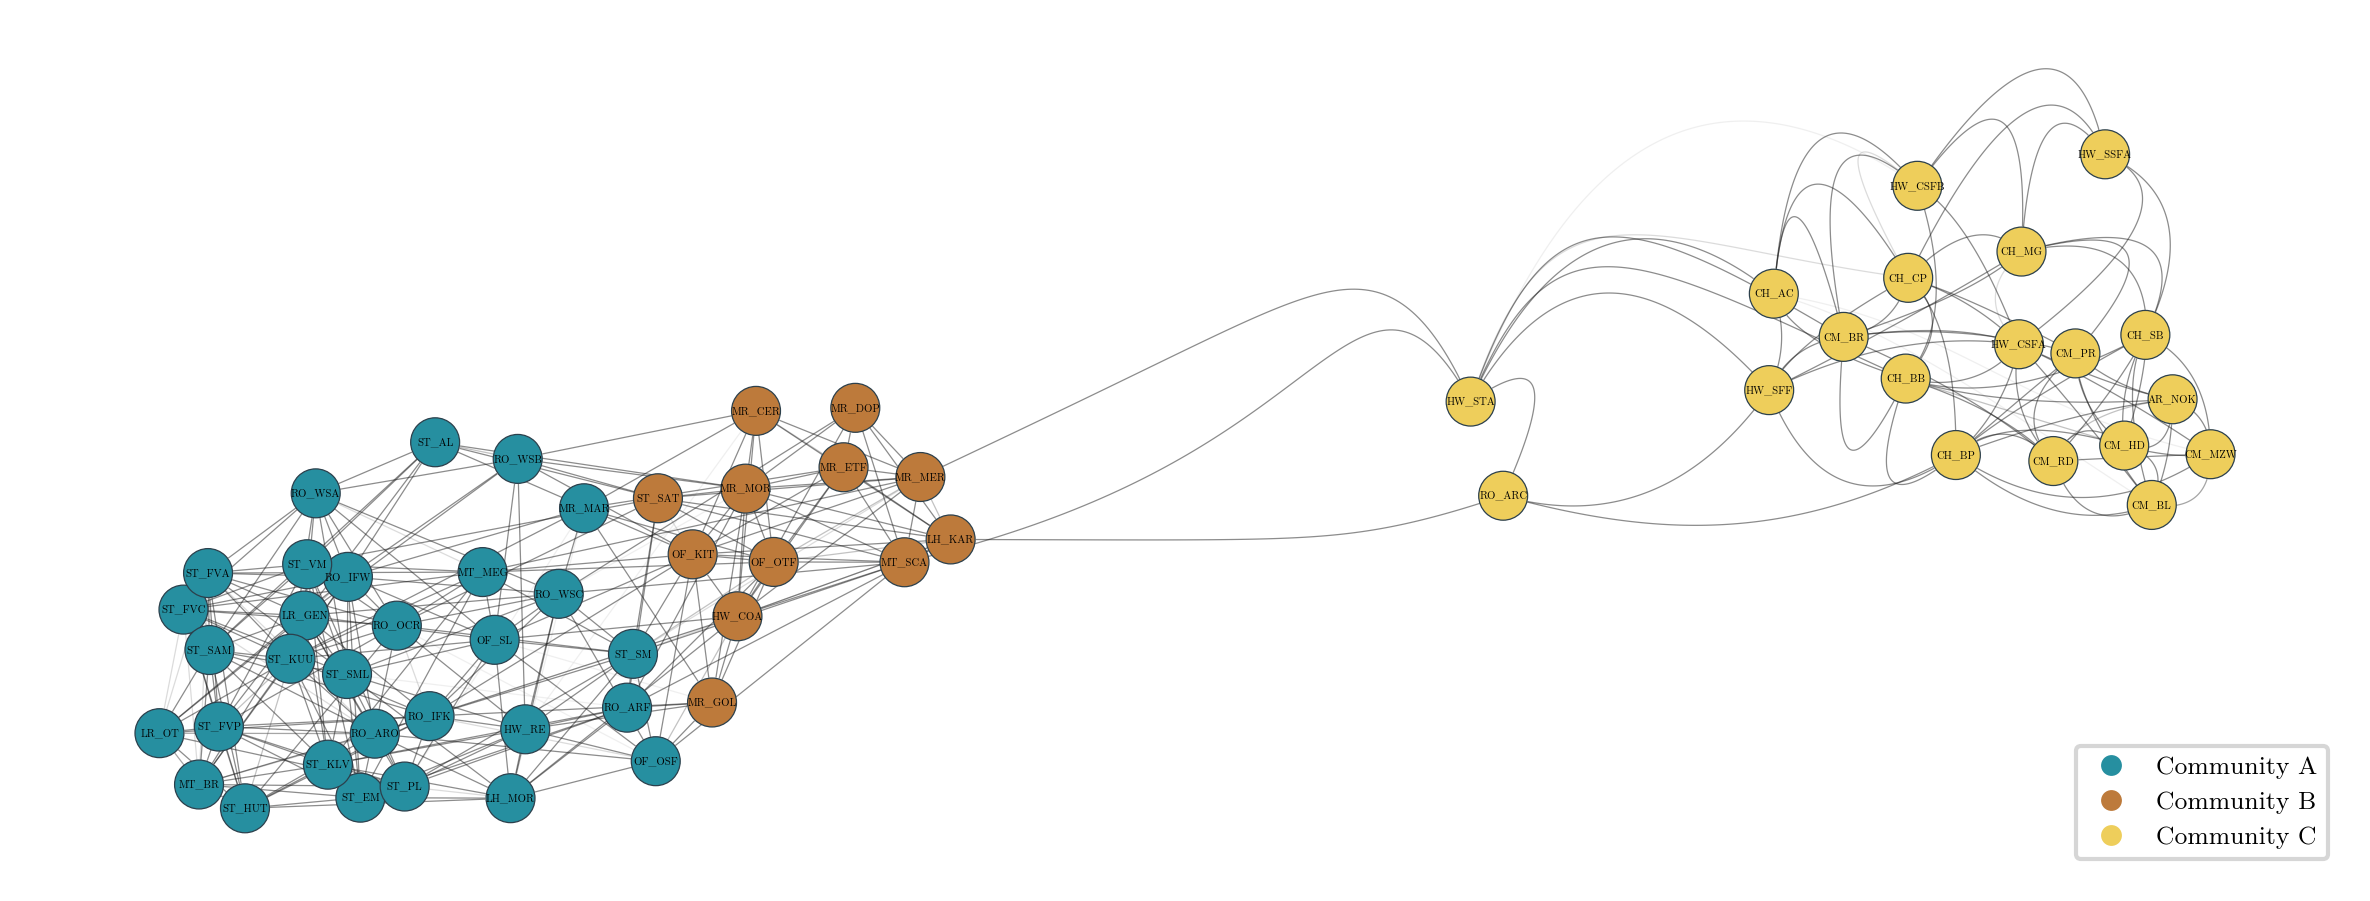

In [84]:
# Map each node to its community id
node_to_community = {}
n_communities = 3
for cid, comm in enumerate(communities):
    for node in comm:
        node_to_community[node] = cid

# Map each community id to a color
community_to_color = {
    0: "#268FA0",  
    1: "#BD7A3B",  
    2: "#EECE5B",
}

# node_color dictionary for Graph plotting
node_color = {
    node: community_to_color[node_to_community[node]]
    for node in G.nodes()
}

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

Graph(
    G,
    node_layout=pos,
    node_size=2,
    node_labels=True,
    node_color=node_color,                 # per-node colors by community
    node_label_fontdict={"size": 2.5},
    node_edge_width=0.1,
    edge_width=0.1,
    edge_layout='curved',
    ax=ax,
)
legend_labels = ['Community A', 'Community B', 'Community C']
patches = [
    plt.Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=community_to_color[cid],
        markersize=6,
        linestyle='None'
    )
    for cid in range(n_communities)
]
plt.legend(patches, legend_labels, loc='lower right', fontsize=6)
plt.tight_layout()
if savePlots:
    plt.savefig(figsDir +'exp01_communities1.pdf', bbox_inches='tight', dpi=300)
plt.show()

# Room-acoustic parameters

The file `allParams.csv` contains, for every room of the dataset, the reverberation
time $T_{20}$, the clarity $C_{50}$, the early lateral energy fraction
$J_\mathrm{LF}$ (columns `JLF_*`), and the direct-to-reverberant ratio DRR in
octave bands from 125 Hz to 4 kHz.

In [85]:
df = pd.read_csv(dataDir + "allParams.csv")

## Summary of the dataset

Single-number values used to describe the dataset in Sec. II.A of the paper:
$T_{20}$ and $C_{50}$ are averaged over the 500 Hz and 1 kHz bands,
$J_\mathrm{LF}$ is averaged over the four bands from 125 Hz to 1 kHz, and
DRR is taken at 1 kHz. The summaries below are computed over all 80 rooms.

In [86]:
# Compute single number values
df["T20"] = (df["T20_500"] + df["T20_1000"])/2
df["C50"] = (df["C50_500"] + df["C50_1000"])/2
df["JLF"] = (df["JLF_125"] + df["JLF_250"] + df["JLF_500"] + df["JLF_1000"])/4

In [87]:
print("Max T20: ", np.max(df["T20"]))
print("Min T20: ", np.min(df["T20"]))
print("Mean T20: ", np.mean(df["T20"]))
print("Std T20: ", np.std(df["T20"]))
print("Median T20: ", np.median(df["T20"]))
print("")
print("Max C50: ", np.max(df["C50"]))
print("Min C50: ", np.min(df["C50"]))
print("Mean C50: ", np.mean(df["C50"]))
print("Std C50: ", np.std(df["C50"]))
print("Median C50: ", np.median(df["C50"]))
print("")
print("Max early JLF: ", np.max(df["JLF"]))
print("Min early JLF: ", np.min(df["JLF"]))
print("Mean early JLF: ", np.mean(df["JLF"]))
print("Std early JLF: ", np.std(df["JLF"]))
print("Median early JLF: ", np.median(df["JLF"]))
print("")
print("Max DRR: ", np.max(df["DRR_1000"]))
print("Min DRR: ", np.min(df["DRR_1000"]))
print("Mean DRR: ", np.mean(df["DRR_1000"]))
print("Std DRR: ", np.std(df["DRR_1000"]))
print("Median DRR: ", np.median(df["DRR_1000"]))


Max T20:  3.073292942636745
Min T20:  0.1221940492723485
Mean T20:  0.8819607929466595
Std T20:  0.7678674141861316
Median T20:  0.4560951325381075

Max C50:  28.440501437151852
Min C50:  -2.210056814956169
Mean C50:  8.711519271688571
Std C50:  7.225716824354488
Median C50:  8.761351569990342

Max early JLF:  0.31562718385846905
Min early JLF:  0.026085838972403054
Mean early JLF:  0.16346627236480585
Std early JLF:  0.06185166645764029
Median early JLF:  0.15788691758821266

Max DRR:  7.74896888032085
Min DRR:  -12.0842638461475
Mean DRR:  -0.5559087547228536
Std DRR:  4.0162704545590024
Median DRR:  0.09763012559836429


Distribution of the parameters in each octave band over all 80 rooms
(Fig. 1 in the paper).

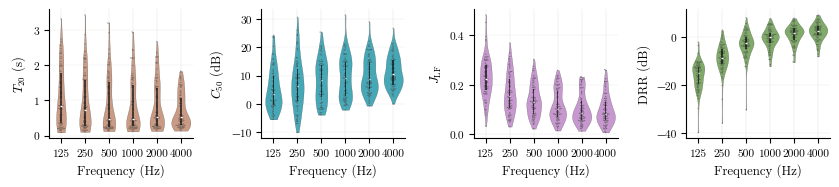

In [88]:
freqLabs = ["125", "250", "500", "1000", "2000", "4000"]

fig, axes = plt.subplots(1,4, figsize=(8.5, 2))

paramColors = ['#CC7D56', '#5AA236', '#00A5BD', '#C173CF'] 

# T20
sns.swarmplot(data=df[["T20_125", "T20_250", "T20_500", "T20_1000", "T20_2000", "T20_4000"]],
               ax=axes[0], 
               color="black",
               facecolors="none",
               linewidth=0.2,
               size=0.6,
               alpha=0.9)
sns.violinplot(data=df[["T20_125", "T20_250", "T20_500", "T20_1000", "T20_2000", "T20_4000"]],
               ax=axes[0], 
               cut=0,
               color=paramColors[0],
               alpha=0.8,
               linewidth=0.2,
               inner=None)
sns.boxplot(
    data=df[["T20_125", "T20_250", "T20_500", "T20_1000", "T20_2000", "T20_4000"]],
    ax=axes[0],
    width=0.06,
    boxprops=dict(facecolor="black", edgecolor="none", alpha=0.6),
    whiskerprops = dict(visible= False),
    medianprops = dict(color = "white", linewidth=1, alpha=1),
    showcaps=False,
    zorder=5
)
axes[0].set_ylabel(r'$T_{20}$ (s)')

# C50
sns.swarmplot(data=df[["C50_125", "C50_250", "C50_500", "C50_1000", "C50_2000", "C50_4000"]],
               ax=axes[1], 
               color="black",
               facecolors="none",
               linewidth=0.2,
               size=0.6,
               alpha=0.9)
sns.violinplot(data=df[["C50_125", "C50_250", "C50_500", "C50_1000", "C50_2000", "C50_4000"]],
               ax=axes[1],
               cut = 0,
               color = paramColors[2],
               alpha=0.8,
               linewidth=0.2,
               inner = None)
sns.boxplot(
    data=df[["C50_125", "C50_250", "C50_500", "C50_1000", "C50_2000", "C50_4000"]],
    ax=axes[1],
    width=0.06,
    boxprops=dict(facecolor="black", edgecolor="none", alpha=0.6),
    whiskerprops = dict(visible= False),
    medianprops = dict(color = "white", linewidth=1, alpha=1),
    showcaps=False,
    showfliers=False,
    zorder=5
)

axes[1].set_ylabel(r'$C_{50}$ (dB)')

# JLF
sns.swarmplot(data=df[["JLF_125", "JLF_250", "JLF_500", "JLF_1000", "JLF_2000", "JLF_4000"]],
               ax=axes[2], 
               color="black",
               facecolors="none",
               linewidth=0.2,
               size=0.6,
               alpha=0.9)
sns.violinplot(data=df[["JLF_125", "JLF_250", "JLF_500", "JLF_1000", "JLF_2000", "JLF_4000"]],
               ax=axes[2],
               cut = 0,
               color = paramColors[3],
               alpha=0.8,
               linewidth = 0.2,
               inner=None)
sns.boxplot(
    data=df[["JLF_125", "JLF_250", "JLF_500", "JLF_1000", "JLF_2000", "JLF_4000"]],
    ax=axes[2],
    width=0.06,
    boxprops=dict(facecolor="black", edgecolor="none", alpha=0.6),
    whiskerprops = dict(visible= False),
    medianprops = dict(color = "white", linewidth=1, alpha=1),
    showcaps=False,
    showfliers=False,
    zorder=5
)
axes[2].set_ylabel(r'$J_\mathrm{LF}$')

sns.swarmplot(data=df[["DRR_125", "DRR_250", "DRR_500", "DRR_1000" , "DRR_2000", "DRR_4000"]],
               ax=axes[3], 
               color="black",
               facecolors="none",
               linewidth=0.2,
               size=0.6,
               alpha=0.9)
sns.violinplot(data=df[["DRR_125", "DRR_250", "DRR_500", "DRR_1000" , "DRR_2000", "DRR_4000"]],
               ax=axes[3],
               cut = 0,
               color = paramColors[1],
               alpha=0.8,
               linewidth = 0.2,
               inner=None) 
sns.boxplot(
    data=df[["DRR_125", "DRR_250", "DRR_500", "DRR_1000" , "DRR_2000", "DRR_4000"]],
    ax=axes[3],
    width=0.06,
    boxprops=dict(facecolor="black", edgecolor="none", alpha=0.6),
    whiskerprops = dict(visible= False),
    medianprops = dict(color = "white", linewidth=1, alpha=1),
    showcaps=False,
    showfliers=False,
    zorder=5
)
axes[3].set_ylabel("DRR (dB)")

# Add lines
for ax in axes.flat:
    ax.yaxis.grid(True, alpha=0.3, linewidth=0.3)
    ax.xaxis.grid(True, alpha=0.4, linewidth=0.3)
    ax.set_xticks(range(len(freqLabs)))
    ax.set_xticklabels(freqLabs)
    ax.set_xlabel("Frequency (Hz)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.xaxis.label.set_fontsize(9)
    ax.yaxis.label.set_fontsize(9)
    ax.tick_params(labelsize=8)


plt.tight_layout()
 
if savePlots:
    plt.savefig(figsDir +'RoomAcousticParams.pdf', bbox_inches='tight', dpi=300)
plt.show()

### Outlier removal

In [89]:
# The movie theater `MT_MEG` has a DRR between -40 and -30 dB in the 125 Hz to 500 Hz bands, far below the rest of the dataset. To keep this room from dominating the PCA, these three values are replaced by the mean of the other rooms in the same bands. This only affects the PCA and LDA below, Fig. 1 and the summaries above use the original values.
filtered_df = df[df["Row"] == "MT_MEG"][["Row", "DRR_125", "DRR_250", "DRR_500", "DRR_1000", "DRR_2000", "DRR_4000"]]
print(filtered_df)

       Row    DRR_125    DRR_250    DRR_500  DRR_1000  DRR_2000  DRR_4000
46  MT_MEG -39.570349 -35.686349 -30.155116 -6.387031   2.16748  3.980576


In [90]:
# Remove outlier contribution by setting their value to the mean
cols = ["DRR_125", "DRR_250", "DRR_500"]
mask = df["Row"] == "MT_MEG"
df.loc[mask, cols] = np.nan
means = df[cols].mean(skipna=True)
df.loc[mask, cols] = means.values

df = df.set_index("Row")

## Principal component analysis

The PCA uses the 24 parameter values of each room (four parameters in six
octave bands) for the 61 rooms of the reduced graph. The parameters are
standardized to zero mean and unit variance first, since they have
different units. The first three principal components explain 53.1%,
26.4%, and 4.0% of the variance.

In [91]:
cols = ["T20_125", "T20_250", "T20_500", "T20_1000", "T20_2000", "T20_4000", 
        "DRR_125", "DRR_250", "DRR_500", "DRR_1000", "DRR_2000", "DRR_4000",
        "C50_125", "C50_250", "C50_500", "C50_1000", "C50_2000", "C50_4000",
        "JLF_125", "JLF_250", "JLF_500", "JLF_1000", "JLF_2000", "JLF_4000"]

T = df.loc[~df.index.isin(outlier_keys), cols]

In [92]:
D = StandardScaler().fit_transform(T.values)

# pca
pca = PCA()
score = pca.fit_transform(D)
coeff = pca.components_.T
latent = pca.explained_variance_
explained = pca.explained_variance_ratio_
mu = pca.mean_

In [93]:
for i, v in enumerate(explained, start=1):
    print(f"PC{i}: {v:.4f}")
    

PC1: 0.5311
PC2: 0.2642
PC3: 0.0400
PC4: 0.0352
PC5: 0.0261
PC6: 0.0218
PC7: 0.0200
PC8: 0.0151
PC9: 0.0118
PC10: 0.0106
PC11: 0.0060
PC12: 0.0038
PC13: 0.0028
PC14: 0.0024
PC15: 0.0020
PC16: 0.0018
PC17: 0.0015
PC18: 0.0012
PC19: 0.0009
PC20: 0.0006
PC21: 0.0005
PC22: 0.0004
PC23: 0.0001
PC24: 0.0001


Quick biplot to visualize the parameter loadings on the first two principal components. This figure is not in the paper.

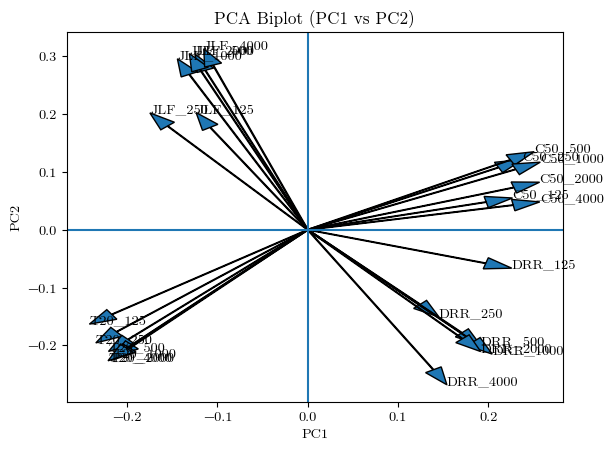

In [94]:
# PC1 vs PC2 biplot (loads first 3 components)
plt.figure()

# loadings
for i, col in enumerate(T.columns):
    plt.arrow(
        0, 0,
        coeff[i, 0], coeff[i, 1],
        head_width=0.02, length_includes_head=True
    )
    plt.text(coeff[i, 0], coeff[i, 1], col)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Biplot (PC1 vs PC2)")
plt.axhline(0)
plt.axvline(0)
plt.show()

## Linear discriminant analysis of the PCA scores

The LDA uses the scores of the rooms on the first three principaln components (`Dim1` to `Dim3`) and the communities as classes. It finds the
projection onto two dimensions (`LD1`, `LD2`) that best separates the three communities. This projection is used only to place the rooms in the
figure; the communities themselves come from the Girvan-Newman community detection algorithm avobe performed on the similarity graph.

- `W2` contains the LDA scalings, i.e., the directions of the three PCA axes in the LDA plane.
- `coeffsProjected` contains the loadings of each room-acoustic parameter projected onto the LDA plane.

In [95]:
# Build Tpca from first 3 PCs
Tpca = pd.DataFrame(
    score[:, :3],
    columns=["Dim1", "Dim2", "Dim3"],
    index=T.index
)

# Assign communities
Tpca["Community"] = pd.NA
Tpca.loc[list(communities[0]), "Community"] = "A"
Tpca.loc[list(communities[1]), "Community"] = "B"
Tpca.loc[list(communities[2]), "Community"] = "C"

# LDA (fitcdiscr)
lda = LinearDiscriminantAnalysis()
lda.fit(Tpca[["Dim1", "Dim2", "Dim3"]], Tpca["Community"])

LinearDiscriminantAnalysis()

In [96]:
W2 = lda.scalings_
score = Tpca[["Dim1", "Dim2", "Dim3"]].to_numpy()
Y = score @ W2
Tpca[["LD1", "LD2"]] = Y[:, :2]

In [97]:
Tpca

,Dim1,Dim2,Dim3,Community,LD1,LD2
Row,,,,,,
AR_NOK,-3.899970,-1.715065,-2.445034,C,4.614901,1.254769
CH_AC,-5.155462,-3.763896,0.254987,C,6.291688,0.515790
CH_BB,-3.158348,-3.404484,0.695395,C,4.387722,0.448742
CH_BP,-2.177817,-4.890453,0.617496,C,4.475796,1.150534
CH_CP,-1.352744,-4.577883,0.616558,C,3.629466,1.152232
...,...,...,...,...,...,...
ST_SAM,3.721913,0.966186,-0.694056,A,-3.425832,0.497793
ST_SAT,0.769280,1.081231,-1.771515,B,-0.903478,0.571273
ST_SM,3.077089,0.219998,-0.383634,A,-2.533087,0.526640


In [98]:
coeffsProjected = coeff[:, 0:3] @ W2

## Communities in the parameter space

To plot the final figure of Experiment I (Fig. 3 in the paper), the graph of the 61 rooms is drawn with each room at its position in the LDA plane (normalized
to the largest coordinate) and colored by community. The arrows on the bottom left show the directions of the three PCA axes in this plane. The arrows on
the bottom right show the projected loadings of each parameter, colored by parameter and labeled with the corresponding octave band center frequency.

In [99]:
coords = Tpca.loc[list(G.nodes), ["LD1", "LD2"]].to_numpy(dtype=float)
pos = {n: xy for n, xy in zip(G.nodes, coords/coords.max())} # Normalize positions for plotting graph

/opt/homebrew/Caskroom/miniconda/base/envs/room-acoustic-memory/lib/python3.9/site-packages/netgraph/_utils.py:360: RuntimeWarning: invalid value encountered in divide
  v = v / np.linalg.norm(v, axis=-1)[:, None] # unit vector


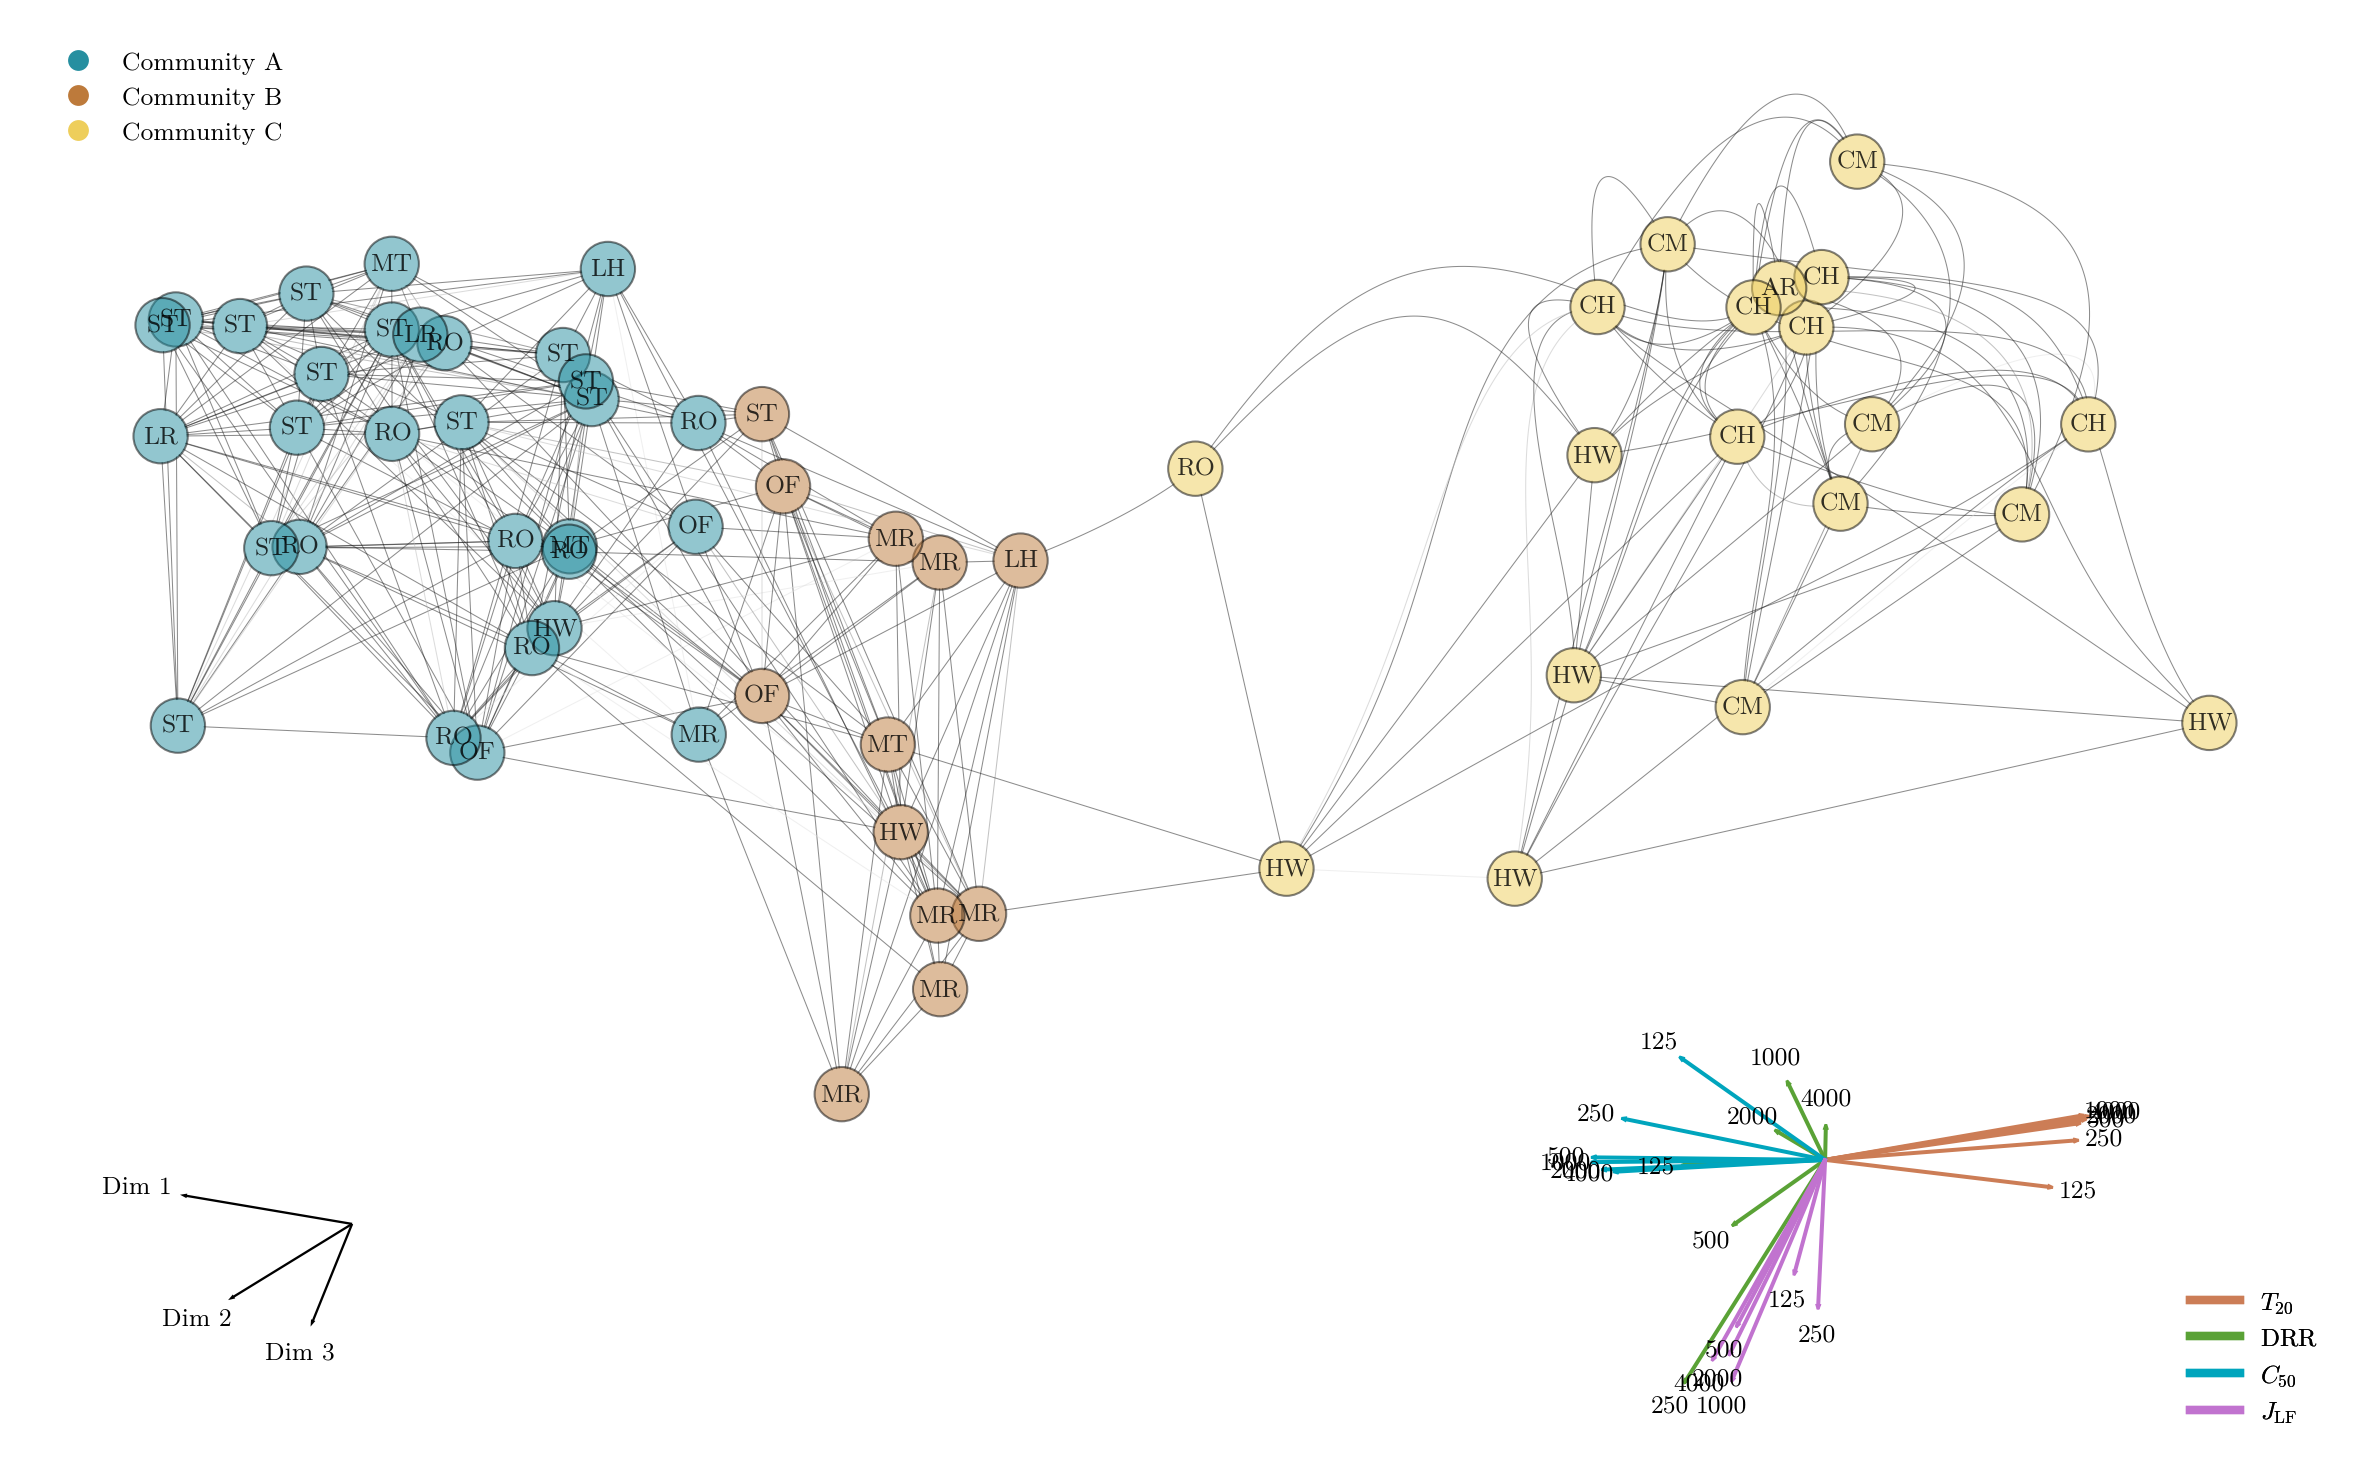

In [100]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
Graph(G, node_layout = pos,
      node_size=2,
      node_labels=False,
      node_color= "#FFFFFF",
      node_edge_width=0,
      edge_width=0.08,
      edge_layout='curved',
      node_zorder=1,
      edge_zorder=0,
      ax=ax)

nodes = list(G.nodes())
xy = np.array([pos[n] for n in nodes])
colors = [node_color[n] for n in nodes]  # per-node colors

# Overlay points;
scat = ax.scatter(
    xy[:, 0], xy[:, 1],
    s=170,
    c = colors,
    edgecolors="#000000",
    linewidths= 0.5,
    zorder=100,
    alpha = 0.5
)



clean_labels = {n: re.sub(r'_.*$', '', str(n)) for n in nodes}

for n in nodes:
    x, y = pos[n]
    ax.text(
        x, y,
        clean_labels[n],
        ha='center',
        va='center',
        fontsize=6,
        color='black',
        alpha = 0.8,
        zorder=150
    )


patches = [
    plt.Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=community_to_color[cid],
        markersize=6,
        linestyle='None'
    )
    for cid in range(n_communities)
]

legend_labels = ['Community A', 'Community B', 'Community C']
legend1 = ax.legend(patches, legend_labels, loc='upper left', fontsize=6, frameon=False)
ax.add_artist(legend1)

# Offset for the PCA axis
offset = np.array([-0.45, -0.55])
quiverScale = 6

ax.quiver(
    np.full(W2.shape[0], offset[0]),  # x0 shifted
    np.full(W2.shape[0], offset[1]),  # y0 shifted
    W2[:, 0],                         # dx
    W2[:, 1],                         # dy
    angles='xy',
    scale_units='xy',
    scale=quiverScale,
    color="k",
    width=0.001,    
    alpha=1,
    headwidth=2,
    headlength=3,
    headaxislength=3,
)
labels = ["Dim 1", "Dim 2", "Dim 3"]

for i, lab in enumerate(labels):
    ax.text(
        offset[0] + W2[i, 0]/quiverScale * 1.25,
        offset[1] + W2[i, 1]/quiverScale * 1.25,
        lab,
        fontsize=6,
        ha="center",
        va="center"
    )

# Offset for the loadings
offset = np.array([0.7, -0.5])
paramColors = ['#CC7D56', '#5AA236', '#00A5BD', '#C173CF']  # Parameter colors
col_bands = [re.sub(r'^[^_]*_', '', str(c)) for c in T.columns]
label_pad = 0.02
scaleFactor = 1.5
    
for i, col in enumerate(T.columns):
    color = paramColors[i // 6 % len(paramColors)]  # group every 6
    dx, dy = coeffsProjected[i, 0]/scaleFactor, coeffsProjected[i, 1]/scaleFactor
    plt.arrow(
        offset[0], offset[1],
        dx, dy,
        linewidth=0.65,
        head_width=0.002, length_includes_head=True,
        color = color,
        alpha = 1
    )

    v = np.array([dx, dy])
    n = np.linalg.norm(v)
    u = v / n  # unit direction

    plt.text(offset[0] + dx + u[0]*label_pad,
             offset[1] + dy + u[1]*label_pad,
             col_bands[i],
             fontsize=6,
             color='black',
             ha='center',
             va='center'
             )

arrow_handles = [plt.Line2D([0], [0], color=c, lw=2) for c in paramColors]
legend2_labels = [r'$T_{20}$', r'$\mathrm{DRR}$', r'$C_{50}$', r'$J_\mathrm{LF}$']

# Place the second legend (choose location to avoid overlap)
legend2 = ax.legend(
    arrow_handles, legend2_labels,
    loc='lower right', fontsize=6, frameon=False,
)

# Keep both legends on the same axes
ax.add_artist(legend2)

plt.tight_layout()
if savePlots:
    plt.savefig(figsDir +'exp01_communities.pdf', bbox_inches='tight', dpi=300)
plt.show() 
